# Initial mango model development

Run top to bottom with the ml-models Python environment. This is a **SharePoint-only exploratory baseline**, not a validated phone-photo classifier. Whole-image inputs can expose handwritten answers; proposed labels and specimen-code groups are unverified. No HF images are silently merged. Raw files and annotations are never edited.

We compare a nearest-centroid classifier and a small trained head on frozen ImageNet ResNet-18 features. Deterministic inputs make this first comparison inexpensive; augmentation and backbone fine-tuning are subsequent experiments. [ResNet-18 input normalization](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html), [transfer-learning workflow](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html).


## 1. Configuration

Thresholds are screening choices, not proof of sufficient data. Start with up to ten classes, at least six images and three known code groups. Select classes without model/test performance. Set `REQUIRE_REVIEWED_CROPS=True` when preparing a fruit-only experiment.


In [1]:
from pathlib import Path
import copy, hashlib, json, random, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image, ImageOps
from pillow_heif import register_heif_opener
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import resnet18, ResNet18_Weights
from torchvision import transforms

register_heif_opener()
HERE = Path.cwd().resolve()
ML_ROOT = next((p for parent in (HERE, *HERE.parents) for p in (parent, parent / 'ml-models')
                if (p / 'data/manifests/sharepoint_gemini/annotations.jsonl').is_file()), None)
if ML_ROOT is None:
    raise FileNotFoundError('Could not locate ml-models.')
SEED = 4914
MIN_IMAGES = 6
MIN_CODE_GROUPS = 3
MAX_CLASSES = 10
BATCH_SIZE = 16
EPOCHS = 60
PATIENCE = 10
LEARNING_RATE = 0.003
USE_CLASS_WEIGHTS = False
REQUIRE_REVIEWED_CROPS = False
# raw_path -> (left, top, right, bottom), in pixels AFTER EXIF orientation correction.
# Add entries only after verifying the crop retains the whole fruit and removes cards/rulers.
REVIEWED_CROPS = {}
# Raw transcription -> human-approved canonical name. These override proposed aliases.
LABEL_OVERRIDES = {}
REJECTED_PATHS = set()
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
# Keep all downloaded weights and model artifacts under this workspace.
torch.hub.set_dir(str(ML_ROOT / 'runs' / '.torch-cache'))
print(f'Device: {DEVICE}; seed: {SEED}')
print('Mode:', 'reviewed crops' if REQUIRE_REVIEWED_CROPS else 'EXPLORATORY whole images / available reviewed crops')

Device: cpu; seed: 4914
Mode: EXPLORATORY whole images / available reviewed crops


## 2. Load labels and filter V1 candidates

Preserve raw labels, use the explicit provisional spelling crosswalk, retain exterior images with known codes, and exclude missing/rejected files. Exact-hash label conflicts are excluded; repeated paths keep the latest timestamp. No labels are guessed from adjacent files.


In [2]:
PROPOSED_ALIASES = {'4- WAY BOMBAY SDG': '4-WAY BOMBAY SDG', 'ALAMPUR BANESAN': 'ALAMPUR BANESHAN', 'BENETT AIPHONSO': 'BENETT ALPHONSO', 'BENETT HIPHONSO': 'BENETT ALPHONSO', 'BENETT-ALPHONSO': 'BENETT ALPHONSO', 'BENNET ALPHONSO': 'BENETT ALPHONSO', 'BESENNARA': 'BESSENARA', 'CHOC ANNON': 'CHOC ANON', 'DUNCAN X JULLIETTE': 'DUNCAN X JULIETTE', 'FIORIGON': 'FLORIGON', 'GIAZIER': 'GLAZIER', 'GLENN X PEACH COBLER': 'GLENN X PEACH COBBLER', 'HIMSIGAR': 'HIMSAGAR', 'HINDI BESSENERA': 'HINDI BESSENARA', 'ITHAMARACA': 'ITAMARACA', 'LUCILE': 'LUCILLE', 'MUIGOBA': 'MULGOBA', 'PILLSBURY-A': 'PILLSBURYA', 'PO PUY KALAY / LEMON MERINGUE': 'PO PUY KALAY/LEMON MERINGUE', 'PO PUY KALAY/ LEMON MERINGUE': 'PO PUY KALAY/LEMON MERINGUE', 'RED ITAMA RACA': 'RED ITAMARACA', 'ROCK DALE SAIGON': 'ROCKDALE SAIGON', 'ROSIGOID': 'ROSIGOLD', 'RUBY X HINDI BESSANARA': 'RUBY X HINDI BESSENARA', 'RUBY X HINDI BESSENCARA': 'RUBY X HINDI BESSENARA', 'SPRINFELS': 'SPRINGFELS', 'TUEHAU': 'TUE HAU', 'YOUNG (EDWARD XKENT 14)': 'YOUNG (EDWARD X KENT 14)'}
manifest_path = ML_ROOT / 'data/manifests/sharepoint_gemini/annotations.jsonl'
with manifest_path.open(encoding='utf-8') as handle:
    records = [json.loads(line) for line in handle if line.strip()]
manifest = pd.json_normalize(records)
manifest['cultivar_raw'] = manifest['annotation.cultivar'].astype('string').str.strip().replace('', pd.NA)
manifest['cultivar'] = manifest.cultivar_raw.str.replace(r'\s+', ' ', regex=True).str.upper().replace(PROPOSED_ALIASES)
for raw, canonical in LABEL_OVERRIDES.items():
    manifest.loc[manifest.cultivar_raw.eq(raw), 'cultivar'] = canonical
manifest['code'] = manifest['annotation.specimen_code'].astype('string').str.upper().str.replace(r'\s+', '', regex=True).replace('', pd.NA)
manifest['view'] = manifest['annotation.view_type'].astype('string').str.strip().str.lower()
manifest = manifest.sort_values('completed_at', kind='stable').drop_duplicates('raw_path', keep='last')
conflicting_hashes = manifest.dropna(subset=['sha256']).groupby('sha256').cultivar.nunique()
conflicting_hashes = set(conflicting_hashes[conflicting_hashes.gt(1)].index)
candidates = manifest.loc[manifest.view.eq('exterior') & manifest.cultivar.notna() & manifest.code.notna()
                          & ~manifest.sha256.isin(conflicting_hashes) & ~manifest.raw_path.isin(REJECTED_PATHS)].copy()
candidates['path'] = candidates.raw_path.map(lambda p: ML_ROOT / p)
missing_files = candidates.loc[~candidates.path.map(Path.is_file)]
candidates = candidates.loc[candidates.path.map(Path.is_file)].copy()
if REQUIRE_REVIEWED_CROPS:
    candidates = candidates.loc[candidates.raw_path.isin(REVIEWED_CROPS)].copy()
print(f'{len(records):,} records -> {len(candidates):,} exterior candidates with labels, codes and existing files.')
print(f'Excluded {len(conflicting_hashes)} conflicting hash groups; {len(missing_files)} missing files.')

1,408 records -> 739 exterior candidates with labels, codes and existing files.
Excluded 0 conflicting hash groups; 0 missing files.


## 3. Group related records and select supported classes

Use code alone across cultivars as a conservative grouping key: a reused location code cannot land in different splits. Exact duplicate hashes join those groups transitively, before redundant files are removed. This guards known relationships; codes are not proof of fruit identity.


In [3]:
parents = {i: i for i in candidates.index}
def find_group(i):
    while parents[i] != i:
        parents[i] = parents[parents[i]]
        i = parents[i]
    return i

def join_group(a, b):
    parents[find_group(b)] = find_group(a)

for key in ['code', 'sha256']:
    seen = {}
    for i, value in candidates[key].items():
        if pd.isna(value) or not str(value).strip():
            continue
        if value in seen:
            join_group(seen[value], i)
        else:
            seen[value] = i
candidates['group'] = [f'g{find_group(i)}' for i in candidates.index]
valid_hash = candidates.sha256.notna() & candidates.sha256.astype('string').str.strip().ne('')
extra_duplicates = valid_hash & candidates.sha256.duplicated(keep='first')
print(f'Removing {extra_duplicates.sum()} redundant exact-image records after grouping.')
candidates = candidates.loc[~extra_duplicates].copy()
coverage = candidates.groupby('cultivar').agg(images=('raw_path', 'size'), groups=('group', 'nunique'))
eligible = coverage.loc[coverage.images.ge(MIN_IMAGES) & coverage.groups.ge(MIN_CODE_GROUPS)]
eligible = eligible.sort_values(['images', 'groups'], ascending=False, kind='stable').head(MAX_CLASSES)
if len(eligible) < 2:
    raise ValueError('Fewer than two supported classes. Review crops/data or adjust the declared screening thresholds.')
class_names = sorted(eligible.index)
class_to_id = {name: i for i, name in enumerate(class_names)}
model_df = candidates.loc[candidates.cultivar.isin(class_names)].copy().reset_index(drop=True)
model_df['class_id'] = model_df.cultivar.map(class_to_id)
display(eligible)
print(f'{len(model_df)} images across {len(class_names)} selected classes; all labels remain provisional unless reviewed.')

Removing 1 redundant exact-image records after grouping.
122 images across 10 selected classes; all labels remain provisional unless reviewed.


,images,groups
cultivar,,
SAIGON,22,6
DUNCAN,16,6
BENETT ALPHONSO,15,5
RUBY,13,6
CARABAO,12,5
EDWARD,10,3
CARRIE,9,5
GRAHAM,9,5
YOUNG,8,5


## 4. Make fixed group-aware train/validation/test splits

Search deterministic group assignments for full class coverage in each split, targeting 60/20/20 image proportions. Never break a group to force proportions. The search uses labels and counts only, never model scores. If impossible, revise the class set or collect independent examples.


In [4]:
def make_group_splits(frame, seed=SEED, attempts=4000):
    groups = sorted(frame.group.unique())
    if len(groups) < 3:
        raise ValueError('At least three independent group proxies are required.')
    rng = np.random.default_rng(seed)
    best, best_score = None, float('inf')
    targets = np.array([0.60, 0.20, 0.20])
    all_classes = set(frame.class_id)
    for _ in range(attempts):
        # Satisfy scarce-class coverage first, then allocate remaining groups.
        assignment = {}
        class_groups = {label: sorted(part.group.unique()) for label, part in frame.groupby('class_id')}
        ordered = sorted(class_groups, key=lambda label: (len(class_groups[label]), rng.random()))
        feasible = True
        for label in ordered:
            available = class_groups[label]
            present = {assignment[g] for g in available if g in assignment}
            missing = [name for name in ['train', 'validation', 'test'] if name not in present]
            unassigned = [g for g in available if g not in assignment]
            if len(unassigned) < len(missing):
                feasible = False
                break
            rng.shuffle(unassigned)
            rng.shuffle(missing)
            for name, group in zip(missing, unassigned):
                assignment[group] = name
        if not feasible:
            continue
        for group in groups:
            if group not in assignment:
                assignment[group] = rng.choice(['train', 'validation', 'test'], p=targets)
        split = frame.group.map(assignment)
        if any(set(frame.loc[split.eq(name), 'class_id']) != all_classes for name in ['train', 'validation', 'test']):
            continue
        fractions = np.array([split.eq(name).mean() for name in ['train', 'validation', 'test']])
        per_class = pd.crosstab(frame.class_id, split).reindex(columns=['train', 'validation', 'test']).div(frame.groupby('class_id').size(), axis=0)
        score = np.abs(fractions - targets).sum() + np.abs(per_class.to_numpy() - targets).mean()
        if score < best_score:
            best, best_score = split, score
    if best is None:
        raise ValueError('No class-complete group split found. Narrow classes/increase data; do not fall back to image-random splits.')
    return best

model_df['split'] = make_group_splits(model_df)
assert model_df.groupby('group').split.nunique().max() == 1
assert model_df.dropna(subset=['sha256']).groupby('sha256').split.nunique().max() == 1
split_counts = pd.crosstab(model_df.cultivar, model_df.split).reindex(columns=['train', 'validation', 'test'], fill_value=0)
assert split_counts.gt(0).all().all()
display(split_counts)
print('Images per split:', model_df.split.value_counts().to_dict())
print('Known code/duplicate groups do not cross splits; unknown relationships can still exist.')

Images per split: {'train': 72, 'test': 25, 'validation': 25}
Known code/duplicate groups do not cross splits; unknown relationships can still exist.


split,train,validation,test
cultivar,,,
BENETT ALPHONSO,7,4,4
CAMBODIANA,5,2,1
CARABAO,8,2,2
CARRIE,4,2,3
DUNCAN,14,1,1
EDWARD,5,2,3
GRAHAM,5,2,2
RUBY,5,3,5
SAIGON,13,6,3


## 5. Decode, crop, preserve shape, and inspect inputs

EXIF orientation is applied before crop coordinates. Convert to RGB, pad to a square, resize to 224×224, and apply ImageNet mean/std. Padding preserves fruit shape and avoids center-cropping fruit edges. No grayscale, aggressive color edits, or automatic cropping. Preview before interpreting any experiment.


Whole-image scores are exploratory and may reflect handwritten labels/backgrounds.


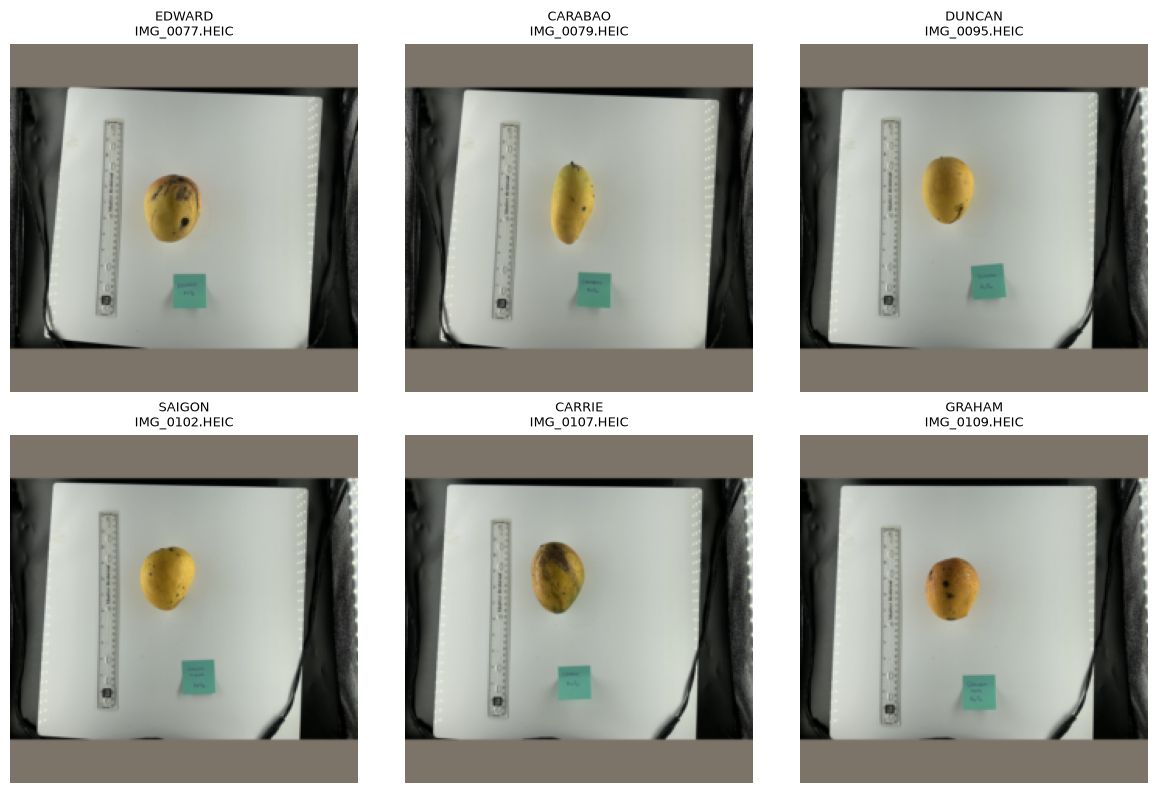

In [5]:
IMAGE_SIZE = 224
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
normalize_tensor = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

def prepare_image(row):
    with Image.open(row.path) as opened:
        image = ImageOps.exif_transpose(opened).convert('RGB')
    if row.raw_path in REVIEWED_CROPS:
        left, top, right, bottom = REVIEWED_CROPS[row.raw_path]
        if not (0 <= left < right <= image.width and 0 <= top < bottom <= image.height):
            raise ValueError(f'Invalid oriented-image crop: {row.raw_path}')
        image = image.crop((left, top, right, bottom))
    elif REQUIRE_REVIEWED_CROPS:
        raise ValueError(f'Missing reviewed crop: {row.raw_path}')
    edge = max(image.size)
    square = Image.new('RGB', (edge, edge), color=(124, 116, 104))
    square.paste(image, ((edge - image.width) // 2, (edge - image.height) // 2))
    return square.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)

preview_rows = model_df.groupby('cultivar', sort=True).head(1).head(6)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, row in zip(axes.flat, preview_rows.itertuples()):
    ax.imshow(prepare_image(row)); ax.set_title(f'{row.cultivar}\n{Path(row.raw_path).name}', fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout(); plt.show()
print('Whole-image scores are exploratory and may reflect handwritten labels/backgrounds.')

## 6. Load the pretrained feature extractor

ResNet-18 is frozen, including batch-normalization running statistics. The first run downloads approximately 45 MB of ImageNet weights into the workspace cache. If download fails, resolve it before training; random weights are not a transfer-learning substitute.


In [6]:
weights = ResNet18_Weights.IMAGENET1K_V1
backbone = resnet18(weights=weights)
feature_size = backbone.fc.in_features
backbone.fc = nn.Identity()
backbone.requires_grad_(False)
backbone = backbone.to(DEVICE).eval()
print(f'Frozen ResNet-18: {feature_size} features per image; {len(class_names)} target classes.')

Frozen ResNet-18: 512 features per image; 10 target classes.


## 7. Extract deterministic features once

This baseline skips augmentation so frozen features can be reused cheaply. Feature extraction performs no fitting on validation/test data; classifier training uses training rows only. Decode failures stop with the offending path rather than silently changing the split.


In [7]:
features_list = []
started = time.time()
with torch.inference_mode():
    for start in range(0, len(model_df), BATCH_SIZE):
        batch_rows = model_df.iloc[start:start + BATCH_SIZE]
        tensors = []
        for row in batch_rows.itertuples():
            try:
                tensors.append(normalize_tensor(prepare_image(row)))
            except Exception as exc:
                raise RuntimeError(f'Image decode/preprocessing failed: {row.raw_path}') from exc
        features_list.append(backbone(torch.stack(tensors).to(DEVICE)).cpu())
features = torch.cat(features_list).clone()
labels = torch.tensor(model_df.class_id.to_numpy(), dtype=torch.long)
assert features.shape == (len(model_df), feature_size)
assert torch.isfinite(features).all()
indices = {name: torch.tensor(np.flatnonzero(model_df.split.eq(name).to_numpy()), dtype=torch.long)
           for name in ['train', 'validation', 'test']}
print(f'Extracted {tuple(features.shape)} features in {time.time() - started:.1f}s.')

Extracted (122, 512) features in 14.2s.


## 8. Define metrics and a cheap centroid baseline

Metrics are multiclass accuracy, macro F1, top-k (k≤3), and per-class precision/recall with support. Centroids average normalized training embeddings. Validation helps compare models; test is used only after fitting and settings are fixed.


In [8]:
def score_predictions(y, scores):
    y = y.cpu(); scores = scores.detach().cpu()
    pred = scores.argmax(1)
    count = len(class_names)
    cm = torch.bincount(y * count + pred, minlength=count * count).reshape(count, count).float()
    tp = cm.diag(); support = cm.sum(1)
    precision = tp / cm.sum(0).clamp_min(1)
    recall = tp / support.clamp_min(1)
    f1 = 2 * precision * recall / (precision + recall).clamp_min(1e-12)
    k = min(3, count)
    metrics = {'accuracy': float(pred.eq(y).float().mean()), 'macro_f1': float(f1.mean()),
               f'top_{k}_accuracy': float(scores.topk(k, dim=1).indices.eq(y[:, None]).any(1).float().mean())}
    details = pd.DataFrame({'class': class_names, 'precision': precision.numpy(), 'recall': recall.numpy(),
                            'f1': f1.numpy(), 'support': support.int().numpy()}).set_index('class')
    return metrics, details, cm

unit_features = nn.functional.normalize(features, dim=1)
centroids = torch.stack([unit_features[indices['train']][labels[indices['train']].eq(i)].mean(0)
                         for i in range(len(class_names))])
centroids = nn.functional.normalize(centroids, dim=1)
centroid_validation = unit_features[indices['validation']] @ centroids.T
print('Centroid validation:', score_predictions(labels[indices['validation']], centroid_validation)[0])

Centroid validation: {'accuracy': 0.1599999964237213, 'macro_f1': 0.086753249168396, 'top_3_accuracy': 0.7200000286102295}


## 9. Train a small head, selecting the best validation checkpoint

Only the linear head learns. Dropout and AdamW regularize it; optional inverse-frequency weights are computed from training data only. Early stopping uses validation loss. No test scores influence fitting. The backbone stays frozen.


Epoch 1: train loss 2.627; val loss 2.642; val macro F1 0.008
Epoch 10: train loss 0.793; val loss 2.275; val macro F1 0.104
Restored epoch 2; 5,130 trainable parameters.


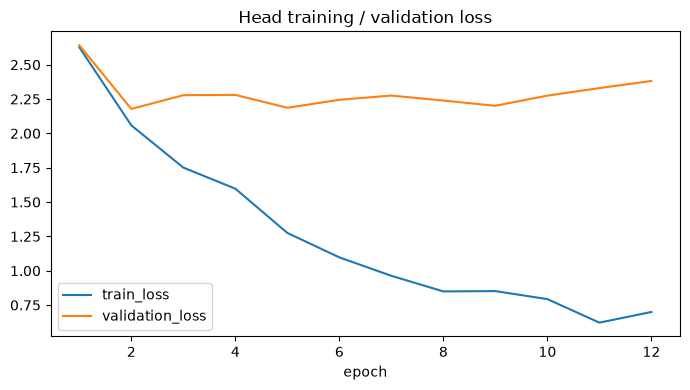

In [9]:
torch.manual_seed(SEED)
head = nn.Sequential(nn.Dropout(0.2), nn.Linear(feature_size, len(class_names))).to(DEVICE)
train_features = features[indices['train']]
train_labels = labels[indices['train']]
loader = DataLoader(TensorDataset(train_features, train_labels), batch_size=BATCH_SIZE, shuffle=True,
                    generator=torch.Generator().manual_seed(SEED), num_workers=0)
training_counts = torch.bincount(train_labels, minlength=len(class_names)).float()
class_weights = (len(train_labels) / (len(class_names) * training_counts)).to(DEVICE) if USE_CLASS_WEIGHTS else None
loss_function = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(head.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
history = []; best_loss = float('inf'); best_state = None; stale = 0
for epoch in range(1, EPOCHS + 1):
    head.train(); loss_total = 0.0
    for x, y in loader:
        optimizer.zero_grad(set_to_none=True)
        loss = loss_function(head(x.to(DEVICE)), y.to(DEVICE))
        loss.backward(); optimizer.step(); loss_total += loss.item() * len(y)
    head.eval()
    with torch.no_grad():
        val_logits = head(features[indices['validation']].to(DEVICE))
        # Unweighted validation loss is comparable with USE_CLASS_WEIGHTS on/off.
        val_loss = nn.functional.cross_entropy(val_logits, labels[indices['validation']].to(DEVICE)).item()
    val_metrics = score_predictions(labels[indices['validation']], val_logits)[0]
    history.append({'epoch': epoch, 'train_loss': loss_total / len(train_labels), 'validation_loss': val_loss, **val_metrics})
    if val_loss < best_loss - 1e-5:
        best_loss = val_loss; best_state = copy.deepcopy(head.state_dict()); best_epoch = epoch; stale = 0
    else:
        stale += 1
    if epoch == 1 or epoch % 10 == 0:
        print(f'Epoch {epoch}: train loss {history[-1]["train_loss"]:.3f}; val loss {val_loss:.3f}; val macro F1 {val_metrics["macro_f1"]:.3f}')
    if stale >= PATIENCE:
        break
head.load_state_dict(best_state); head.eval()
print(f'Restored epoch {best_epoch}; {sum(p.numel() for p in head.parameters()):,} trainable parameters.')
history_df = pd.DataFrame(history).set_index('epoch')
history_df[['train_loss', 'validation_loss']].plot(figsize=(7, 4), title='Head training / validation loss')
plt.tight_layout(); plt.show()

## 10. Final evaluation on the fixed held-out split

Run after configuration and model selection are settled. Comparing frozen centroid and the validation-selected head is descriptive: do not use these test results for subsequent tuning. Small per-class supports make scores unstable; uncropped inputs do not establish fruit recognition.


EXPLORATORY results: provisional labels/groups; label-card shortcuts remain possible without approved crops.


,accuracy,macro_f1,top_3_accuracy
training_majority,0.04,0.008,0.16
centroid,0.36,0.209,0.68
linear_head,0.32,0.143,0.68


,precision,recall,f1,support
class,,,,
BENETT ALPHONSO,0.364,1.000,0.533,4
CAMBODIANA,0.000,0.000,0.000,1
CARABAO,0.000,0.000,0.000,2
CARRIE,0.000,0.000,0.000,3
DUNCAN,0.000,0.000,0.000,1
EDWARD,0.500,0.333,0.400,3
GRAHAM,0.000,0.000,0.000,2
RUBY,0.000,0.000,0.000,5
SAIGON,0.333,1.000,0.500,3


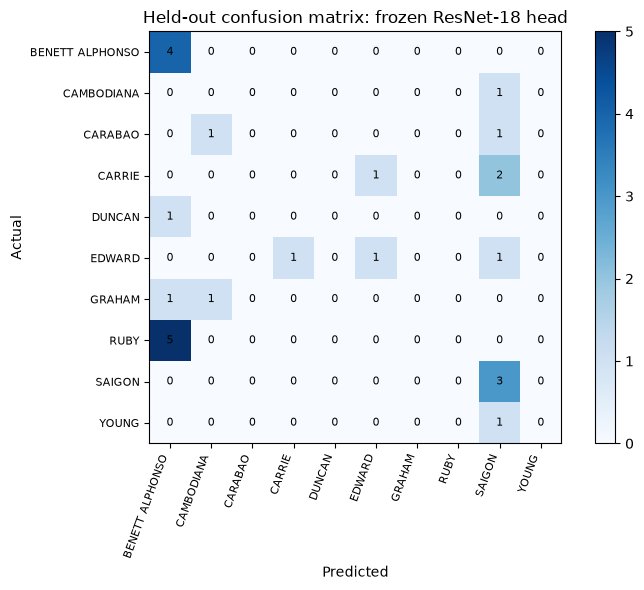

In [10]:
with torch.no_grad():
    head_test_scores = head(features[indices['test']].to(DEVICE)).cpu()
centroid_test_scores = unit_features[indices['test']] @ centroids.T
head_metrics, per_class_metrics, confusion = score_predictions(labels[indices['test']], head_test_scores)
centroid_metrics = score_predictions(labels[indices['test']], centroid_test_scores)[0]
majority_id = int(training_counts.argmax())
majority_scores = torch.zeros((len(indices['test']), len(class_names)))
majority_scores[:, majority_id] = 1
majority_metrics = score_predictions(labels[indices['test']], majority_scores)[0]
display(pd.DataFrame({'training_majority': majority_metrics, 'centroid': centroid_metrics, 'linear_head': head_metrics}).T.round(3))
display(per_class_metrics.round(3))
fig, ax = plt.subplots(figsize=(8, 6))
plot = ax.imshow(confusion.numpy(), cmap='Blues')
ax.set_xticks(range(len(class_names)), class_names, rotation=70, ha='right', fontsize=8)
ax.set_yticks(range(len(class_names)), class_names, fontsize=8)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Held-out confusion matrix: frozen ResNet-18 head')
for i in range(len(class_names)):
    for j in range(len(class_names)):
        ax.text(j, i, int(confusion[i, j]), ha='center', va='center', fontsize=8)
fig.colorbar(plot, ax=ax); plt.tight_layout(); plt.show()
print('EXPLORATORY results: provisional labels/groups; label-card shortcuts remain possible without approved crops.')

## 11. Save one reproducible experiment artifact

A fresh run directory contains the trained model, class mapping, preprocessing settings, exact split membership, provenance, and metrics as JSON/PyTorch artifacts. No extra CSV reports. The raw annotation mapping CSV remains separate and unchanged.


In [11]:
from datetime import datetime, timezone
run_dir = ML_ROOT / 'runs' / ('initial-resnet18-' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
run_dir.mkdir(parents=True, exist_ok=False)
checkpoint = {'backbone': {k: v.cpu() for k, v in backbone.state_dict().items()},
              'head': {k: v.cpu() for k, v in head.state_dict().items()}, 'centroids': centroids,
              'class_names': class_names, 'feature_size': feature_size}
torch.save(checkpoint, run_dir / 'model.pt')
experiment = {'seed': SEED, 'backbone': 'resnet18', 'weights': 'IMAGENET1K_V1',
              'torch_version': str(torch.__version__), 'manifest_sha256': hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
              'mode': 'reviewed_crops' if REQUIRE_REVIEWED_CROPS else 'exploratory_full_images',
              'preprocessing': {'image_size': IMAGE_SIZE, 'mean': MEAN, 'std': STD, 'aspect_preserving_padding': True, 'augmentation': False},
              'class_names': class_names, 'proposed_aliases': PROPOSED_ALIASES, 'label_overrides': LABEL_OVERRIDES,
              'reviewed_crops': REVIEWED_CROPS, 'selection': {'min_images': MIN_IMAGES, 'min_groups': MIN_CODE_GROUPS, 'max_classes': MAX_CLASSES},
              'training': {'epochs_limit': EPOCHS, 'best_epoch': best_epoch, 'patience': PATIENCE,
                           'learning_rate': LEARNING_RATE, 'class_weights': USE_CLASS_WEIGHTS, 'dropout': 0.2, 'weight_decay': 0.01},
              'split_rows': model_df[['raw_path', 'sha256', 'cultivar', 'code', 'group', 'class_id', 'split']].to_dict('records'),
              'test_metrics': {'majority': majority_metrics, 'centroid': centroid_metrics, 'head': head_metrics},
              'history': history_df.reset_index().to_dict('records')}
(run_dir / 'experiment.json').write_text(json.dumps(experiment, indent=2), encoding='utf-8')
print(f'Saved model and experiment record: {run_dir}')

Saved model and experiment record: /Users/danielgeorge/Desktop/coding/cis4914-senior-project-code/ml-models/runs/initial-resnet18-20261004T184643176226Z


## What to improve next

Review labels and fruit crops first. Then compare mild training-only augmentation, a second pretrained backbone, and cautiously fine-tuned upper layers using the same splits. Audit HF shared-class images before adding them. Keep a separate phone-photo evaluation set. Avoid interpreting high whole-image accuracy as evidence of mango-only recognition.
